In [1]:
import os

os.environ["TF_GPU_ALLOCATOR"] = "cuda_malloc_async"  # flexible async allocator

import tensorflow as tf
# Must configure memory growth BEFORE any pipeline stage imports initialize TF GPU
for gpu in tf.config.list_physical_devices("GPU"):
    tf.config.experimental.set_memory_growth(gpu, True)

I0000 00:00:1792847962.857107   14990 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [10]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.vgg16 import preprocess_input

import numpy as np
import pandas as pd


In [3]:


os.getcwd()

'/home/shlok/Personal_Projects/chest-cancer-classifier/Chest-Cancer-Classifier/research'

In [4]:
os.chdir('../')

In [5]:
import tensorflow as tf

model = tf.keras.models.load_model("artifacts/training/model.h5")

I0000 00:00:1792847969.383908   14990 gpu_process_state.cc:208] Using CUDA malloc Async allocator for GPU: 0
I0000 00:00:1792847969.385588   14990 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [6]:
val_datagen = ImageDataGenerator(preprocessing_function=preprocess_input)

val_generator = val_datagen.flow_from_directory(
    directory='artifacts/data_preparation/prepared/test',
    target_size=(224, 224),
    batch_size=16,
    class_mode='categorical', 
    shuffle=False              # CRITICAL: Keep False to preserve prediction order
)

Found 269 images belonging to 4 classes.


In [7]:
class_names = list(val_generator.class_indices.keys())
y_true = val_generator.classes

In [8]:
test_loss, test_acc = model.evaluate(val_generator)

I0000 00:00:1792847970.672708   14990 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.
I0000 00:00:1792847971.123774   15104 service.cc:153] XLA service 0x7d16040327b0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1792847971.123814   15104 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 3050 Laptop GPU, Compute Capability 8.6 (Driver: 13.1.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1792847971.146774   15104 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1792847971.226084   15104 cuda_dnn.cc:461] Loaded cuDNN version 92700
I0000 00:00:1792847981.239716   15104 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


17/17 ━━━━━━━━━━━━━━━━━━━━ 18s 429ms/step - accuracy: 0.7026 - loss: 2.0432


In [11]:
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")


Test Loss: 2.0432
Test Accuracy: 0.7026


In [12]:
predictions = model.predict(val_generator)
y_pred = np.argmax(predictions, axis=1)

17/17 ━━━━━━━━━━━━━━━━━━━━ 4s 154ms/step


In [13]:
y_pred

array([0, 0, 0, 3, 0, 0, 3, 0, 1, 0, 0, 3, 0, 3, 1, 1, 0, 0, 0, 0, 3, 3,
       0, 0, 0, 0, 0, 0, 0, 3, 0, 1, 1, 0, 3, 3, 3, 1, 0, 0, 3, 0, 0, 3,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 3, 0, 3, 0, 0, 0, 0, 0,
       0, 1, 0, 0, 3, 3, 1, 1, 1, 0, 0, 1, 3, 1, 0, 0, 0, 3, 0, 0, 3, 0,
       0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 3, 3, 3, 0, 0, 1, 3, 0, 0,
       0, 2, 0, 3, 0, 3, 3, 0, 0, 3, 1, 1, 1, 1, 1, 2, 1, 0, 1, 3, 1, 1,
       1, 1, 1, 1, 1, 1, 0, 1, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 0, 3, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 3, 0, 1, 1, 1, 1, 1, 2, 1, 2, 2, 2,
       0, 2, 3, 3, 0, 3, 3, 0, 3, 3, 3, 0, 1, 3, 3, 1, 3, 1, 3, 3, 3, 3,
       0, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 1, 0, 3, 3,
       3, 3, 3, 0, 3, 3, 3, 3, 3, 1, 3, 3, 3, 1, 3, 3, 3, 3, 3, 3, 3, 0,
       3, 1, 0, 1, 0, 1, 3, 3, 3, 0, 3, 3, 3, 3, 3, 3, 3, 3, 3, 1, 1, 3,
       3, 3, 3, 1, 3])

Classification Report:

                precision    recall  f1-score   support

adenocarcinoma       0.81      0.63      0.71       120
    large_cell       0.58      0.78      0.67        51
        normal       0.71      0.62      0.67         8
 squamous_cell       0.69      0.76      0.72        90

      accuracy                           0.70       269
     macro avg       0.70      0.70      0.69       269
  weighted avg       0.72      0.70      0.70       269



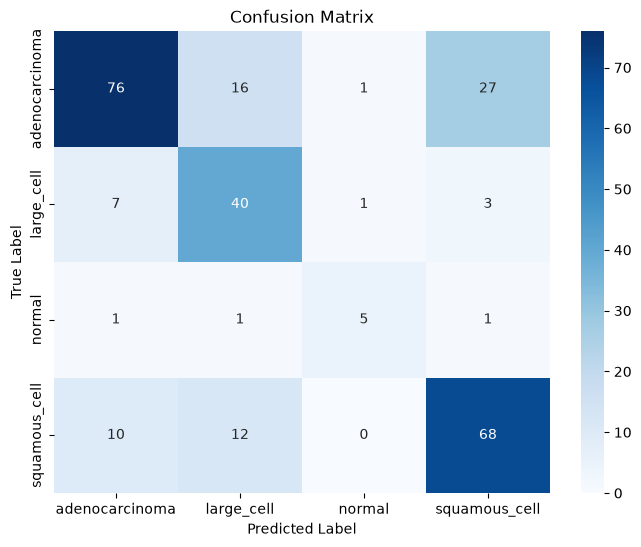

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Print precision, recall, f1-score per class
print("Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_names))

# Plot Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()


In [15]:
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │       100,356 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,815,046 (56.51 MB)

 Trainable params: 100,356 (392.02 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

 Optimizer params: 2 (12.00 B)